# MiniReasoner: Phase 4 Arithmetic SFT Evaluation & Interactive Playground

Evaluate **Phase 4 Arithmetic SFT** checkpoints from **Azure Blob Storage** (`minireasoner`) or a local `.pt` file, and test questions interactively in a single cell.

### What This Notebook Does:
- **SFT-First Run Discovery**: Automatically prioritizes active `stage="sft"` runs in Azure + Databricks MLflow (`RUN_ID = None`), or loads an explicit `RUN_ID` / `LOCAL_CHECKPOINT`.
- **Before vs. After Lineage**: Optionally loads the SFT checkpoint's `parent_run_id` base model so you can compare **SFT vs. Base Pre-trained** side-by-side.
- **Training Curve Diagnostics**: Plots `val_arith_loss`, interval train loss, `story_val_loss`, exact-match %, valid-format %, and per-operation accuracy curves.
- **Stratified Arithmetic Benchmark (`val` by default)**: Scores Exact Match, Valid Format, per-operation accuracy (`add`, `sub`, `mul`, `div`), per-category accuracy (`1d`/`2d`/`3d`, carry/borrow, signed, zero/unit), wording generalization, and sample `[MISS]` cases while keeping `test.jsonl` sealed until Phase 6.
- **Story Retention Check**: Verifies `SimpleStories` generation remains coherent after SFT.
- **Type & Ask Playground (Section 9)**: Type any math problem (e.g. `28 + 53`, `-144 / (-12)`, `What is 47 + 8?`) or story prompt in one cell and run immediately (plus an optional continuous prompt loop).

## 1. Project Environment Setup
Locate the MiniReasoner repository root, load `.env` credentials (Azure Blob Storage & Databricks MLflow), and configure `sys.path`.

In [16]:
import os
import sys
from pathlib import Path
from dotenv import load_dotenv

working_dir = Path.cwd().resolve()
project_root = next(
    (path for path in (working_dir, *working_dir.parents)
     if (path / "src" / "main.py").is_file() and (path / "pyproject.toml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook inside the MiniReasoner repository.")

load_dotenv(project_root / ".env")
print(f"Project root located at: {project_root}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

Project root located at: C:\Users\sampa\Dev\MiniReasoner


## 2. Hardware & Device Configuration (CPU / CUDA GPU)
Automatically uses CUDA BF16 (Ampere+) / FP32 when a GPU is available, or portable CPU Float32 locally.

In [17]:
import torch

DEVICE_PREFERENCE = "auto"  # 'auto', 'cuda', or 'cpu'

if DEVICE_PREFERENCE == "auto":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
elif DEVICE_PREFERENCE in ("cuda", "cpu"):
    if DEVICE_PREFERENCE == "cuda" and not torch.cuda.is_available():
        print("Notice: CUDA requested but unavailable; falling back to CPU.")
        device = torch.device("cpu")
    else:
        device = torch.device(DEVICE_PREFERENCE)
else:
    raise ValueError(f"Unknown device preference: {DEVICE_PREFERENCE}")

if device.type == "cuda":
    cap = torch.cuda.get_device_capability(0)
    dtype = torch.bfloat16 if (torch.cuda.is_bf16_supported() and cap[0] >= 8) else torch.float32
    hw_info = f"{torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB VRAM)"
else:
    dtype = torch.float32
    hw_info = f"CPU ({torch.get_num_threads()} threads)"

print(f"Active Device: {device.type.upper()} | Hardware: {hw_info} | Dtype: {dtype}")

Active Device: CPU | Hardware: CPU (4 threads) | Dtype: torch.float32


## 3. Discover & Download SFT Checkpoint
- Leave `RUN_ID = None` to automatically select the newest active **SFT** run (`stage="sft"`) in Azure Blob Storage + Databricks MLflow.
- Choose `CHECKPOINT_ALIAS = "latest"` (highest step), `"best"` (lowest `val_arith_loss`), or `"step-N"`.
- Or set `LOCAL_CHECKPOINT = "path/to/checkpoint.pt"` for offline evaluation.

In [18]:
import re
from src.infra.checkpoint_store import CheckpointStore
from src.infra.tracking import discover_azure_runs
from src.settings import AZURE_CONTAINER, MLFLOW_EXPERIMENT

RUN_ID = None                 # Set an SFT run ID, or None to auto-pick newest active SFT run
CHECKPOINT_ALIAS = "latest"   # 'latest', 'best', or 'step-N'
LOCAL_CHECKPOINT = None       # Optional local .pt path for offline evaluation

checkpoints_dir = project_root / "checkpoints"
checkpoints_dir.mkdir(parents=True, exist_ok=True)
selected_snapshot = None

if LOCAL_CHECKPOINT is not None:
    cached_checkpoint_path = Path(LOCAL_CHECKPOINT).expanduser().resolve()
    if not cached_checkpoint_path.is_file():
        raise FileNotFoundError(f"Local checkpoint not found: {cached_checkpoint_path}")
    run_id = cached_checkpoint_path.parent.name
    print(f"Using offline local checkpoint: {cached_checkpoint_path}")
else:
    discovered = discover_azure_runs(
        AZURE_CONTAINER,
        experiment=MLFLOW_EXPERIMENT,
        preferred_stages=("sft",),
    )
    if not discovered:
        raise FileNotFoundError(f"No checkpoints found in Azure container '{AZURE_CONTAINER}'.")

    print(f"Discovered {len(discovered)} run(s) in Azure container '{AZURE_CONTAINER}' (SFT runs prioritized):\n")
    print(f"{'Run ID':<36}{'Stage':<10}{'MLflow State':<14}{'Snapshots':<11}{'Last Updated (UTC)'}")
    print("-" * 92)
    for row in discovered:
        ts = row["last_modified"].strftime("%Y-%m-%d %H:%M:%S") if row["last_modified"] else "N/A"
        print(f"{row['run_id']:<36}{row['mlflow_stage']:<10}{row['mlflow_state']:<14}{row['blob_count']:<11}{ts}")

    run_id = RUN_ID or discovered[0]["run_id"]
    print(f"\nSelected run: {run_id}")

    store = CheckpointStore(AZURE_CONTAINER, run_id, experiment=MLFLOW_EXPERIMENT)
    versions = store._versions()
    if not versions:
        raise FileNotFoundError(f"No valid checkpoints found for run {run_id!r}.")

    print(f"\nTop checkpoints by validation loss for {run_id} ({len(versions)} total):\n")
    print(f"{'Rank':<6}{'Step':<8}{'Val Loss':<12}{'Train Mean':<12}{'Filename'}")
    print("-" * 85)
    for rank, snap in enumerate(versions[:5], start=1):
        print(f"#{rank:<5}{snap.step:<8}{snap.val_loss:<12.4f}{snap.train_loss_interval_mean:<12.4f}{snap.name[:45]}...")

    if CHECKPOINT_ALIAS == "best":
        selected_snapshot = versions[0]
    elif CHECKPOINT_ALIAS == "latest":
        selected_snapshot = max(versions, key=lambda item: item.step)
    elif alias_match := re.fullmatch(r"step-(\d+)", CHECKPOINT_ALIAS):
        step_num = int(alias_match[1])
        selected_snapshot = next((item for item in versions if item.step == step_num), None)
        if selected_snapshot is None:
            raise FileNotFoundError(f"Step {step_num} not found in run {run_id}.")
    else:
        raise ValueError("CHECKPOINT_ALIAS must be 'best', 'latest', or 'step-N'.")

    print(
        f"\n--> Selected ({CHECKPOINT_ALIAS}): Step {selected_snapshot.step:,} | "
        f"Val Arith Loss: {selected_snapshot.val_loss:.4f} | "
        f"Train Mean: {selected_snapshot.train_loss_interval_mean:.4f}"
    )

    run_cache_dir = checkpoints_dir / run_id
    run_cache_dir.mkdir(parents=True, exist_ok=True)
    cached_checkpoint_path = run_cache_dir / f"{CHECKPOINT_ALIAS}_step_{selected_snapshot.step}_{selected_snapshot.sha256[:8]}.pt"
    if not cached_checkpoint_path.is_file():
        print(f"Downloading checkpoint to {cached_checkpoint_path}...")
        store.download(CHECKPOINT_ALIAS, cached_checkpoint_path)
        print("Download complete and verified via SHA-256 checksum.")
    else:
        size_mb = cached_checkpoint_path.stat().st_size / (1024 * 1024)
        print(f"Using locally cached checkpoint: {cached_checkpoint_path} ({size_mb:.2f} MB)")

Discovered 6 run(s) in Azure container 'minireasoner' (SFT runs prioritized):

Run ID                              Stage     MLflow State  Snapshots  Last Updated (UTC)
--------------------------------------------------------------------------------------------
ef3cc27cede44edf90ff5f205a2f71d6    sft       active        16         2026-11-25 17:43:41
e8996fa3b67f48c8951cfd20f68ab40b    sft       active        6          2026-11-25 17:17:13
23a72f3aa8d6487ca401b92b22ae229c    pretrain  active        53         2026-11-24 19:09:03
655ddf770790468d988bbb0375fd5aa4    pretrain  active        48         2026-11-24 09:22:26
f9a6d03c46af4a378895622a82ace4c3    sft       deleted       6          2026-11-25 17:12:04
c26cf6e5ffc749e69b298d27f33ca243    pretrain  deleted       4          2026-11-24 15:11:38

Selected run: ef3cc27cede44edf90ff5f205a2f71d6

Top checkpoints by validation loss for ef3cc27cede44edf90ff5f205a2f71d6 (16 total):

Rank  Step    Val Loss    Train Mean  Filename
-----------

## 4. Load SFT Weights, Lineage Metadata & Optional Base Model
Loads the SFT checkpoint, prints training/dataset metadata, and optionally loads its `parent_run_id` Base model (`COMPARE_WITH_BASE = True`) for before-vs-after comparison.

In [19]:
from tokenizers import Tokenizer
from src.core.checkpoint import build_model_config, load_checkpoint, resolve_base_checkpoint
from src.core.model import GPT
from src.core.tokenizer import EOS

COMPARE_WITH_BASE = False  # Set False to skip downloading/loading the parent pre-trained Base checkpoint

checkpoint = load_checkpoint(cached_checkpoint_path)
checkpoint.pop("optimizer", None)

tokenizer = Tokenizer.from_str(checkpoint["tokenizer_json"])
model_config = build_model_config(checkpoint)
model = GPT(model_config).to(device).eval()
model.load_state_dict(checkpoint["model"])
checkpoint.pop("model", None)
if device.type == "cuda" and dtype == torch.bfloat16:
    model = model.to(dtype=torch.bfloat16)

sft_step = int(checkpoint.get("step", selected_snapshot.step if selected_snapshot else 0))
sft_stage = checkpoint.get("stage", "unknown")
parent_run_id = checkpoint.get("parent_run_id")
parent_step = checkpoint.get("parent_checkpoint_step")
retention_ratio = checkpoint.get("retention_ratio")
arith_manifest = checkpoint.get("arith_manifest") or {}
metrics_history = checkpoint.get("metrics", [])
total_params = sum(p.numel() for p in model.parameters())

print("=" * 66)
print("MINIREASONER SFT CHECKPOINT SUMMARY")
print("=" * 66)
print(f"Run ID / Stage:        {run_id} (stage={sft_stage}, step={sft_step:,})")
print(f"Parent Base Lineage:   run={parent_run_id} | step={parent_step}")
print(f"Architecture:          {model_config.n_layer}L / {model_config.n_head}H / {model_config.n_embd}D | {model_config.pos_encoding.upper()} ctx={model_config.context_length:,}")
print(f"Parameters / Vocab:    {total_params:,} (~{total_params / 1e6:.2f}M) | vocab={model_config.vocab_size:,}")
if arith_manifest:
    print(
        f"SFT Dataset Config:    {arith_manifest.get('generator_version')} | ops={arith_manifest.get('ops')} | "
        f"max_digits={arith_manifest.get('max_digits')} | negatives={arith_manifest.get('allow_negative')} | "
        f"samples_per_op={arith_manifest.get('samples_per_op')}"
    )
if retention_ratio is not None:
    print(f"Story Retention Ratio: {retention_ratio:.2f}")
print("=" * 66)

base_model = None
base_tokenizer = None
if COMPARE_WITH_BASE and parent_run_id:
    try:
        base_alias = f"step-{int(parent_step)}" if parent_step else "latest"
        base_path, base_ckpt = resolve_base_checkpoint(
            run_id=str(parent_run_id),
            alias=base_alias,
            azure_container=AZURE_CONTAINER,
            checkpoints_dir=checkpoints_dir,
        )
        base_ckpt.pop("optimizer", None)
        base_tokenizer = Tokenizer.from_str(base_ckpt["tokenizer_json"])
        base_cfg = build_model_config(base_ckpt)
        base_model = GPT(base_cfg).to(device).eval()
        base_model.load_state_dict(base_ckpt["model"])
        del base_ckpt
        if device.type == "cuda" and dtype == torch.bfloat16:
            base_model = base_model.to(dtype=torch.bfloat16)
        print(f"Loaded parent Base model for comparison: {base_path.name}")
    except Exception as exc:
        print(f"Skipping Base comparison ({type(exc).__name__}: {exc})")
        base_model = None

MINIREASONER SFT CHECKPOINT SUMMARY
Run ID / Stage:        ef3cc27cede44edf90ff5f205a2f71d6 (stage=sft, step=8,000)
Parent Base Lineage:   run=23a72f3aa8d6487ca401b92b22ae229c | step=26047
Architecture:          10L / 8H / 512D | ROPE ctx=1,024
Parameters / Vocab:    32,049,152 (~32.05M) | vocab=1,024
SFT Dataset Config:    arith_v2 | ops=['add', 'sub', 'mul', 'div'] | max_digits=3 | negatives=True | samples_per_op=12000
Story Retention Ratio: 0.10


## 5. SFT Training Curves: Arith Loss, Exact Match, Retention & Per-Op Progress
Visualizes all metrics recorded in the SFT checkpoint (`val_loss` / `val_arith_loss`, `story_val_loss`, `val_exact_match`, `val_valid_format`, and per-op accuracy).

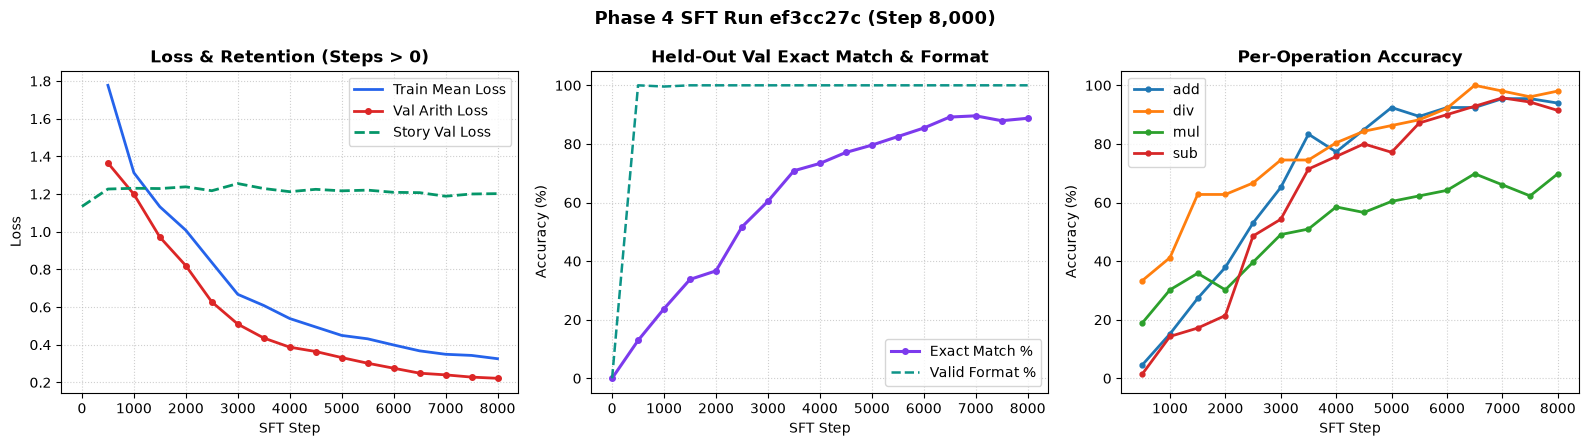

Step 0 Baseline Val Arith Loss: 8.8161 | Latest: 0.2217 (Step 8,000)
Exact Match: 0.0% (Step 0) -> 88.8% (Latest) | Peak: 89.6% (Step 7,000)
Story Val Loss: 1.1341 (Step 0) -> 1.2021 (Step 8,000)


In [20]:
if not metrics_history:
    print("No logged metrics history stored in this checkpoint.")
else:
    steps = [m["step"] for m in metrics_history]
    val_loss = [(m["step"], m["val_loss"]) for m in metrics_history if m.get("val_loss") is not None]
    train_mean = [(m["step"], m["train_loss_interval_mean"]) for m in metrics_history if m.get("train_loss_interval_mean") is not None]
    story_loss = [(m["step"], m["story_val_loss"]) for m in metrics_history if m.get("story_val_loss") is not None]
    exact_match = [(m["step"], m["val_exact_match"] * 100.0) for m in metrics_history if m.get("val_exact_match") is not None]
    valid_fmt = [(m["step"], m["val_valid_format"] * 100.0) for m in metrics_history if m.get("val_valid_format") is not None]

    op_keys = sorted({k for m in metrics_history for k in m if k.startswith("val_acc_op_")})

    try:
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=100)

        if train_mean:
            tm_pts = [pt for pt in train_mean if pt[0] > 0] or train_mean
            axes[0].plot([s for s, _ in tm_pts], [v for _, v in tm_pts], label="Train Mean Loss", color="#2563eb", linewidth=2)
        if val_loss:
            vl_pts = [pt for pt in val_loss if pt[0] > 0] or val_loss
            axes[0].plot([s for s, _ in vl_pts], [v for _, v in vl_pts], label="Val Arith Loss", color="#dc2626", linewidth=2, marker="o", markersize=4)
        if story_loss:
            axes[0].plot([s for s, _ in story_loss], [v for _, v in story_loss], label="Story Val Loss", color="#059669", linewidth=2, linestyle="--")
        axes[0].set_title("Loss & Retention (Steps > 0)", fontweight="bold")
        axes[0].set_xlabel("SFT Step")
        axes[0].set_ylabel("Loss")
        axes[0].grid(True, linestyle=":", alpha=0.6)
        axes[0].legend()

        if exact_match:
            axes[1].plot([s for s, _ in exact_match], [v for _, v in exact_match], label="Exact Match %", color="#7c3aed", linewidth=2.2, marker="o", markersize=4)
        if valid_fmt:
            axes[1].plot([s for s, _ in valid_fmt], [v for _, v in valid_fmt], label="Valid Format %", color="#0d9488", linewidth=1.8, linestyle="--")
        axes[1].set_title("Held-Out Val Exact Match & Format", fontweight="bold")
        axes[1].set_xlabel("SFT Step")
        axes[1].set_ylabel("Accuracy (%)")
        axes[1].set_ylim(-5, 105)
        axes[1].grid(True, linestyle=":", alpha=0.6)
        axes[1].legend()

        if op_keys:
            for k in op_keys:
                pts = [(m["step"], m[k] * 100.0) for m in metrics_history if m.get(k) is not None]
                if pts:
                    axes[2].plot([s for s, _ in pts], [v for _, v in pts], label=k.removeprefix("val_acc_op_"), linewidth=2, marker="o", markersize=3.5)
            axes[2].set_title("Per-Operation Accuracy", fontweight="bold")
            axes[2].set_xlabel("SFT Step")
            axes[2].set_ylabel("Accuracy (%)")
            axes[2].set_ylim(-5, 105)
            axes[2].grid(True, linestyle=":", alpha=0.6)
            axes[2].legend()
        else:
            lr_pts = [(m["step"], m["lr"]) for m in metrics_history if m.get("lr") is not None]
            if lr_pts:
                axes[2].plot([s for s, _ in lr_pts], [v * 1e4 for _, v in lr_pts], color="#ea580c", linewidth=2)
                axes[2].set_title("Learning Rate (x1e-4)", fontweight="bold")
                axes[2].set_xlabel("SFT Step")
                axes[2].grid(True, linestyle=":", alpha=0.6)

        fig.suptitle(f"Phase 4 SFT Run {run_id[:8]} (Step {sft_step:,})", fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.show()
    except ImportError:
        print("matplotlib not installed; skipping charts.")

    if val_loss:
        print(f"Step 0 Baseline Val Arith Loss: {val_loss[0][1]:.4f} | Latest: {val_loss[-1][1]:.4f} (Step {val_loss[-1][0]:,})")
    if exact_match:
        best_em_step, best_em = max(exact_match, key=lambda x: x[1])
        print(f"Exact Match: {exact_match[0][1]:.1f}% (Step 0) -> {exact_match[-1][1]:.1f}% (Latest) | Peak: {best_em:.1f}% (Step {best_em_step:,})")
    if story_loss:
        print(f"Story Val Loss: {story_loss[0][1]:.4f} (Step 0) -> {story_loss[-1][1]:.4f} (Step {story_loss[-1][0]:,})")

## 6. Held-Out Arithmetic Evaluation (`val` Split Breakdown & Miss Inspection)
Evaluates the SFT model on stratified held-out problems from the prepared arithmetic dataset matching the checkpoint's `arith_manifest`.

- Keeps `EVAL_SPLIT = "val"` by default so `test.jsonl` stays sealed until Phase 6 (`ALLOW_SEALED_TEST = False` safety lock).
- Scales `MAX_EVAL_PROBLEMS` automatically (`480` on CUDA GPU, `120` on CPU; set `None` to score the entire split).

In [21]:
import time
from src.core.generate import generate_text
from src.data.arithmetic import (
    load_or_restore_arithmetic_dataset,
    score_arithmetic_completion,
    select_stratified_eval_problems,
)
from src.settings import SFT_DATA_DEFAULTS

EVAL_SPLIT = "val"          # Keep 'val' during Phase 4 tuning; flip only in Phase 6
ALLOW_SEALED_TEST = False   # Safety guard against accidental test leakage
MAX_EVAL_PROBLEMS = 480 if device.type == "cuda" else 120  # None = evaluate full split
EVAL_SEED = int(arith_manifest.get("seed", SFT_DATA_DEFAULTS["seed"]))

if EVAL_SPLIT == "test" and not ALLOW_SEALED_TEST:
    raise RuntimeError("Sealed test split is locked for Phase 6. Set ALLOW_SEALED_TEST = True only for final release testing.")

ops_cfg = arith_manifest.get("ops", SFT_DATA_DEFAULTS["ops"])
max_digits_cfg = int(arith_manifest.get("max_digits", SFT_DATA_DEFAULTS["max_digits"]))
neg_cfg = bool(arith_manifest.get("allow_negative", SFT_DATA_DEFAULTS["allow_negative"]))
samples_cfg = int(arith_manifest.get("samples_per_op", SFT_DATA_DEFAULTS["samples_per_op"]))

try:
    dataset_dir, arith_splits, ds_manifest = load_or_restore_arithmetic_dataset(
        ops=ops_cfg,
        max_digits=max_digits_cfg,
        allow_negative=neg_cfg,
        samples_per_op=samples_cfg,
        seed=EVAL_SEED,
        use_drive=True,
    )
except Exception as exc:
    raise FileNotFoundError(
        f"Could not load prepared dataset ({type(exc).__name__}: {exc}). "
        f"Run `bash scripts/prepare_sft_data.sh` or ensure data/sft/arithmetic contains the matching split."
    ) from exc

pool = arith_splits[EVAL_SPLIT]
eval_items = select_stratified_eval_problems(pool, MAX_EVAL_PROBLEMS or 0, seed=EVAL_SEED) if MAX_EVAL_PROBLEMS else list(pool)
max_ans_tokens = max(24, max_digits_cfg * 2 + 6)

print(f"Loaded split '{EVAL_SPLIT}' from {dataset_dir.name} ({len(eval_items):,}/{len(pool):,} stratified problems).")
t0 = time.perf_counter()

eval_records = []
per_op = {}
per_cat = {}
passes, misses = [], []

for item in eval_items:
    raw = generate_text(model, tokenizer, item.prompt, max_new_tokens=max_ans_tokens, device=device, temperature=0.0)
    verdict = score_arithmetic_completion(raw, item.answer)
    eval_records.append((item, raw, verdict))

    op_s = per_op.setdefault(item.op, [0, 0])
    op_s[1] += 1
    cat_s = per_cat.setdefault(item.category, [0, 0])
    cat_s[1] += 1
    if verdict["exact_match"]:
        op_s[0] += 1
        cat_s[0] += 1
        passes.append((item, raw, verdict))
    else:
        misses.append((item, raw, verdict))

elapsed = time.perf_counter() - t0
n_total = len(eval_records)
n_correct = sum(1 for _, _, v in eval_records if v["exact_match"])
n_formatted = sum(1 for _, _, v in eval_records if v["valid_format"])

print("\n" + "=" * 78)
print(f"ARITHMETIC EVALUATION SUMMARY ({EVAL_SPLIT.upper()} | Step {sft_step:,} | {elapsed:.1f}s on {device.type.upper()})")
print("=" * 78)
print(f"Exact Match Accuracy: {n_correct}/{n_total} ({n_correct / max(1, n_total) * 100:.1f}%)")
print(f"Valid Format Rate:    {n_formatted}/{n_total} ({n_formatted / max(1, n_total) * 100:.1f}%)")
print("-" * 78)
print("Per-Operation Accuracy:")
for op_name, (ok, cnt) in sorted(per_op.items()):
    print(f"  {op_name:<8} {ok:>4}/{cnt:<4} ({ok / max(1, cnt) * 100:5.1f}%)")

print("-" * 78)
print(f"{'Category':<24}{'Correct':<12}{'Accuracy'}")
print("-" * 48)
for cat_name, (ok, cnt) in sorted(per_cat.items(), key=lambda kv: (-kv[1][0] / max(1, kv[1][1]), kv[0])):
    pct = ok / max(1, cnt) * 100
    bar = "#" * int(round(pct / 5))
    print(f"{cat_name:<24}{f'{ok}/{cnt}':<12}{pct:5.1f}%  {bar}")

print("\nSample Passes (up to 6 non-zero/non-unit when available):")
interesting_passes = [r for r in passes if "zero" not in r[0].category and "unit" not in r[0].category]
for item, raw, _ in (interesting_passes or passes)[:6]:
    print(f"  [PASS] {item.category:<20} | {item.prompt.replace(chr(10), ' ')} -> {raw.strip()!r}")

print("\nSample Misses (up to 8):")
for item, raw, _ in misses[:8]:
    print(f"  [MISS] {item.category:<20} | {item.prompt.replace(chr(10), ' ')} -> {raw.strip()[:40]!r} (expected {item.answer})")

if base_model is not None and eval_items:
    sample_cmp = eval_items[: min(24, len(eval_items))]
    base_ok = sum(
        1 for ex in sample_cmp
        if score_arithmetic_completion(
            generate_text(base_model, base_tokenizer, ex.prompt, max_new_tokens=max_ans_tokens, device=device, temperature=0.0),
            ex.answer,
        )["exact_match"]
    )
    sft_ok = sum(1 for _, _, v in eval_records[: len(sample_cmp)] if v["exact_match"])
    print("\n" + "-" * 78)
    print(f"Paired Subset ({len(sample_cmp)} items): Base={base_ok}/{len(sample_cmp)} ({base_ok / len(sample_cmp) * 100:.1f}%) -> SFT={sft_ok}/{len(sample_cmp)} ({sft_ok / len(sample_cmp) * 100:.1f}%)")

Loaded split 'val' from arith_v2_add-sub-mul-div_d3_signed_n12000_s42 (120/4,802 stratified problems).

ARITHMETIC EVALUATION SUMMARY (VAL | Step 8,000 | 14.3s on CPU)
Exact Match Accuracy: 107/120 (89.2%)
Valid Format Rate:    120/120 (100.0%)
------------------------------------------------------------------------------
Per-Operation Accuracy:
  add        33/36   ( 91.7%)
  div        24/25   ( 96.0%)
  mul        17/24   ( 70.8%)
  sub        33/35   ( 94.3%)
------------------------------------------------------------------------------
Category                Correct     Accuracy
------------------------------------------------
add_1d_carry            2/2         100.0%  ####################
add_1d_no_carry         2/2         100.0%  ####################
add_2d_carry            5/5         100.0%  ####################
add_2d_no_carry         5/5         100.0%  ####################
add_3d_carry            5/5         100.0%  ####################
add_equal               2/2       

## 7. Prompt Wording Generalization & Story Retention Check
Checks whether the SFT model handles alternate question phrasings (`Calculate ...`, `a + b =`, `plus`/`times`, English number words) on held-out problems, and verifies `SimpleStories` generation remains fluent.

In [22]:
from src.data.arithmetic import canonical_problem, render_examples

N_VARIANT_PROBS = 16 if device.type == "cuda" else 8
variant_stats = {}

probe_problems = []
for item in eval_items:
    parts = item.canonical_id.split(":")
    if len(parts) == 3:
        prob = canonical_problem(parts[0], int(parts[1]), int(parts[2]))
        probe_problems.append(prob)
    if len(probe_problems) >= N_VARIANT_PROBS:
        break

for prob in probe_problems:
    for ex in render_examples(prob, include_variants=True):
        if ex.variant.endswith("_commuted"):
            continue
        pred = generate_text(model, tokenizer, ex.prompt, max_new_tokens=max_ans_tokens, device=device, temperature=0.0)
        verdict = score_arithmetic_completion(pred, ex.answer)
        st = variant_stats.setdefault(ex.variant, [0, 0])
        st[1] += 1
        st[0] += int(verdict["exact_match"])

print("=" * 66)
print(f"WORDING GENERALIZATION ({len(probe_problems)} held-out problems)")
print("=" * 66)
for vname, (ok, cnt) in sorted(variant_stats.items()):
    print(f"  {vname:<18} {ok:>3}/{cnt:<3} ({ok / max(1, cnt) * 100:5.1f}%)")

story_prompts = [
    "Once upon a time, there was a little",
    "One day, Lily found a secret",
    "Mia had a little dog named",
]
print("\n" + "=" * 66)
print("SIMPLESTORIES RETENTION SANITY CHECK (Greedy)")
print("=" * 66)
for sp in story_prompts:
    out = generate_text(model, tokenizer, sp, max_new_tokens=60, device=device, temperature=0.0)
    print(f"Prompt: {sp!r}")
    print(f"  SFT:  {sp}{out.strip()}")
    if base_model is not None:
        b_out = generate_text(base_model, base_tokenizer, sp, max_new_tokens=60, device=device, temperature=0.0)
        print(f"  Base: {sp}{b_out.strip()}")
    print()

WORDING GENERALIZATION (8 held-out problems)
  calculate            7/8   ( 87.5%)
  canonical            7/8   ( 87.5%)
  equation             7/8   ( 87.5%)
  word_numbers         6/8   ( 75.0%)
  word_op              7/8   ( 87.5%)

SIMPLESTORIES RETENTION SANITY CHECK (Greedy)
Prompt: 'Once upon a time, there was a little'
  SFT:  Once upon a time, there was a littlegirl named Mia who loved to play. She would run around the yard, laughing and shouting. One day, she found a shiny stone. It sparkled like stars. Mia picked it up and felt a warm glow. She thought it was special.

Prompt: 'One day, Lily found a secret'
  SFT:  One day, Lily found a secretdoor in the woods. It was small and covered with vines. She opened it and saw a bright light. "What is this?" she wondered. She stepped inside and gasped. There were tiny creatures dancing and singing.

Prompt: 'Mia had a little dog named'
  SFT:  Mia had a little dog namedLeo. He was barking loudly, and Mia felt a little scared. "What 

## 8. Raw Prompt Playground (Raw Input -> Raw Output)
Type your exact raw `PROMPT` string and run the cell to see the model's exact raw completion (no automatic formatting or pass/fail checks).

In [31]:
from src.core.generate import generate_text

# Type exact raw input (examples: "What is 28 + 53?\nAnswer:", "do you know 44 + 3?", "Once upon a time")
PROMPT = "do you know the value of 200 + 800?\nAnswer:"
TEMPERATURE = 0.0      # 0.0 = greedy (best for math), 0.7 = sampling (stories)
MAX_NEW_TOKENS = 48

raw_output = generate_text(
    model,
    tokenizer,
    PROMPT,
    max_new_tokens=MAX_NEW_TOKENS,
    device=device,
    temperature=TEMPERATURE,
)
print(raw_output)

1000


In [ ]:
# Optional live typing loop (set True to prompt interactively; type 'quit' or empty line to exit)
# In single-line input(), use \\n for a newline (e.g. What is 28 + 53?\\nAnswer:).
START_LIVE_PROMPT = False

if START_LIVE_PROMPT:
    from src.core.generate import generate_text

    while True:
        raw_in = input("\nPrompt> ")
        if raw_in.strip().lower() in ("", "quit", "exit", "q"):
            break
        print(generate_text(model, tokenizer, raw_in.replace("\\n", "\n"), max_new_tokens=64, device=device, temperature=0.0))